# Assignment 2 - Layer Merging with USR, Remove-and-Patch, and Neuron Fusion

**Course:** CS613 NLP, IIT Gandhinagar | **Model:** GPT-2 small (124M, 12 blocks, hidden 768) | **Data:** WikiText-2, DBpedia, AG News, IMDb (Sec. 3b/16-17) | **Primary metric:** perplexity (lower is better)

**What this notebook is:** the Experiment half of Assignment 2 (100 pts: implementation + results). The Report half (LaTeX PDF) is mapped in Section 12.

**Three new methods (from `layer_merging_methods.txt`):**
- **P3 / USR - Union-Select-Reconstruct:** keep the best 3072 of 6144 MLP neurons from both blocks side-by-side, refit readout in closed form.
- **Q1 / R&P - Remove-and-Patch:** keep one real block, replace the other with a tiny mean + low-rank patch.
- **Q2 / NF - Correlation-Guided Neuron Fusion:** pair neurons that fire together, average their inputs, refit outputs.

**How to run (Colab T4):**
1. `Runtime > Change runtime type > T4 GPU`.
2. Run top to bottom. Start with `MODE = "quick"` (smoke test). Then set `MODE = "full"` for report numbers.
3. Fit uses TRAIN only. Best pair/method is picked on VALIDATION. TEST is evaluated once at the end.

In [1]:
!pip install -q transformers==5.16.1 datasets accelerate pandas psutil matplotlib scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 35.6 MB/s eta 0:00:00


## 0. Imports and device

*Instructor note: one import per concern so failures are easy to locate.*

In [2]:
import torch
import transformers
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

PyTorch: 2.11.0+cu130
Transformers: 5.16.1
device: cuda


In [3]:
import random
import numpy as np
import math
import time
import gc
import copy
import re

## 1. Reproducibility

Fixed seed for all shuffling / random-pair controls. Deterministic methods need one run; randomised controls use `SEED + 1000*L + run`.

In [4]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print("seed:", SEED)

seed: 42


## 2. Model: GPT-2 small

We reload a fresh model for every variant so merges never leak into each other.

In [5]:
from transformers import AutoTokenizer, AutoModelForCausalLM
MODEL_ID = "openai-community/gpt2"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.model_max_length = int(1e12)  # we chunk manually; silence length warnings

def load_fresh_model():
    m = AutoModelForCausalLM.from_pretrained(MODEL_ID)
    m.config.use_cache = False
    m.eval()
    return m

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [6]:
# Compatibility probe: some transformers versions return a tuple from a block, others a bare tensor.
# Custom patch blocks below mirror whatever the installed version does.
_probe = load_fresh_model().to(DEVICE)
print("blocks:", len(_probe.transformer.h), "| hidden:", _probe.config.n_embd)
with torch.no_grad():
    _tin = torch.zeros(1, 2, _probe.config.n_embd).to(DEVICE)
    _out = _probe.transformer.h[0](_tin)
    RETURN_TUPLE = isinstance(_out, (tuple, list))
print("Block returns tuple:", RETURN_TUPLE)
del _probe; gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

blocks: 12 | hidden: 768
Block returns tuple: False


## 3. Dataset: WikiText-2

**Used:** `Salesforce/wikitext`, config `wikitext-2-raw-v1` (same as Assignment 1).
- `train` -> fit all merges (calibration tokens only).
- `validation` -> pick best pair/method.
- `test` -> reported once at the end.
- Empty lines are dropped (`join_nonempty`) so PPL is not diluted by blank articles.

*Report pointer (Datasets, 5 pts): bias discussion (Wikipedia-only, formal written English), bottleneck (long-tail rare tokens dominate PPL), and train/val/test roles belong in the PDF; the code here enforces the no-leakage split.*

In [7]:
from datasets import load_dataset
dataset = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")
print(dataset)

def join_nonempty(split):
    # Drop None / whitespace-only articles before joining.
    return "\n\n".join(x for x in split["text"] if x is not None and x.strip())

train_text = join_nonempty(dataset["train"])
validation_text = join_nonempty(dataset["validation"])
test_text = join_nonempty(dataset["test"])
print("chars:", len(train_text), len(validation_text), len(test_text))

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})
chars: 10940522 1147070 1291402


### 3b. New test-only eval sets (DBpedia, AG News, IMDb)

Four eval datasets in total (WikiText-2 + these three). Per the result-format spec these three are **TEST-only**: no fitting ever touches them (all merges still fit on WikiText-2 TRAIN). Texts are character pre-capped (~6 chars/token headroom); `calculate_ppl` then caps tokens exactly.

In [8]:
def _pick_field(cols, cands):
    for f in cands:
        if f in cols:
            return f
    raise KeyError(f"none of {cands} in {cols}")

def load_eval_text(hf_ids, split="test", cap_chars=None, label=""):
    # Tries Hub ids in order (canonical first, mirror fallback). Returns one joined string.
    ds, used = None, None
    for cand in hf_ids:
        try:
            ds = load_dataset(cand, split=split); used = cand; break
        except Exception as e:
            print(f"  [{label}] skip {cand}: {type(e).__name__}")
    assert ds is not None, f"could not load {label}"
    cols = ds.column_names
    if "content" in cols and "title" in cols:  # DBpedia_14
        texts = [((t or "") + "\n" + (c or "")) for t, c in zip(ds["title"], ds["content"])]
    else:  # AG News / IMDb
        f = _pick_field(cols, ["text", "content", "document", "review"])
        texts = list(ds[f])
    text = "\n\n".join(x for x in texts if x and str(x).strip())
    if cap_chars is not None:
        text = text[:cap_chars]
    print(f"  [{label}] {used}/{split}: {len(texts)} docs, {len(text):,} chars kept")
    return text

# NOTE: NEW_EVAL_TOKENS lives in Sec. 5; fall back to the quick value on out-of-order runs.
_new_cap = globals().get("NEW_EVAL_TOKENS", 8000) * 6
dbpedia_text = load_eval_text(["dbpedia_14", "fancyzhx/dbpedia_14"], split="test", cap_chars=_new_cap, label="DBpedia")
ag_text = load_eval_text(["ag_news", "fancyzhx/ag_news"], split="test", cap_chars=_new_cap, label="AG News")
imdb_text = load_eval_text(["imdb", "stanfordnlp/imdb"], split="test", cap_chars=_new_cap, label="IMDb")

README.md:   0%|          | 0.00/7.64k [00:00<?, ?B/s]

  [DBpedia] skip dbpedia_14: HfUriError


README.md:   0%|          | 0.00/7.64k [00:00<?, ?B/s]

dbpedia_14/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  106MB            

dbpedia_14/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

  [IMDb] stanfordnlp/imdb/test: 25000 docs, 48,000 chars kept


## 4. Metrics

**Primary:** perplexity (PPL) on WikiText-2 - standard for language-model compression, directly comparable to Assignment 1.

Textbook definition used here: `PP(W) = P(w_1...w_N)^(-1/N)` (inverse geometric mean of the sequence probability). The code implements exactly this as `exp(mean NLL)` over non-overlapping 512-token chunks - identical math, token-weighted.
**Secondary (per brief Part 3/5):** normalised hidden-state MSE `||pred-Y2||^2 / Var(Y2)`, parameter count, latency.

In [9]:
def calculate_ppl(model, text, block_size=512, max_tokens=None):
    """Non-overlapping-chunk PPL; identical chunks for every variant."""
    model.eval()
    ids = tokenizer(text, return_tensors="pt", add_special_tokens=False)["input_ids"][0]
    if max_tokens is not None:
        ids = ids[:max_tokens]
    n_blocks = len(ids) // block_size
    total_nll, total_tok = 0.0, 0
    with torch.no_grad():
        for i in range(n_blocks):
            x = ids[i*block_size:(i+1)*block_size].unsqueeze(0).to(DEVICE)
            out = model(input_ids=x, labels=x, use_cache=False)
            c = x.numel() - 1
            total_nll += out.loss.item() * c
            total_tok += c
    return math.exp(total_nll / total_tok)

In [10]:
def parameter_count(m):
    """Total params - used for the matched -5.7% comparison group."""
    return sum(p.numel() for p in m.parameters())

def norm_mse(pred, target):
    """Normalised hidden error from the brief (fixes scale/outlier dominance)."""
    return ((pred - target) ** 2).mean().item() / (target.var().item() + 1e-12)

In [11]:
@torch.no_grad()
def measure_latency(model, text, seq_len=256, repeats=10):
    """Forward-pass ms on fixed input; same GPU/seq/repeats for all."""
    model.eval()
    ids = tokenizer(text, return_tensors="pt", add_special_tokens=False)["input_ids"][:, :seq_len].to(DEVICE)
    for _ in range(5):  # warm-up
        _ = model(ids, use_cache=False)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    s = time.perf_counter()
    for _ in range(repeats):
        _ = model(ids, use_cache=False)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return 1000.0 * (time.perf_counter() - s) / repeats

def free_model(m):
    del m; gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

In [12]:
# Original baseline (validation) - everything below is a delta vs this row.
from torch import nn
original_model = load_fresh_model().to(DEVICE)
# NOTE: EVAL_TOKENS is defined in Section 5; default smoke value used here if re-run out of order.
_baseline_ppl = calculate_ppl(original_model, validation_text, max_tokens=globals().get("EVAL_TOKENS", 10000))
_baseline_params = parameter_count(original_model)
print(f"Original GPT-2 val PPL ~ {_baseline_ppl:.2f} | params={_baseline_params:,}")
free_model(original_model)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Original GPT-2 val PPL ~ 29.65 | params=124,439,808


## 5. Experiment config

`quick` = smoke test (minutes). `full` = report numbers (50k fit tokens per brief, full-validation eval, 3 random seeds).

In [13]:
MODE = "quick"  # change to "full" for the final report
if MODE == "quick":
    FIT_TOKENS = 8192    # calibration tokens for every fit (TRAIN only)
    CORR_TOKENS = 4096  # subsample for the 6144x6144 correlation (memory)
    EVAL_TOKENS = 10000  # validation tokens per PPL eval
    RANDOM_RUNS = 1
    LAT_REP = 10
else:
    FIT_TOKENS = 50000
    CORR_TOKENS = 16384
    EVAL_TOKENS = None  # full split
    RANDOM_RUNS = 3
    LAT_REP = 30
RIDGE = 1e-3  # ridge strength (scaled by mean Gram diagonal)
NEW_EVAL_TOKENS = 8000 if MODE == "quick" else 30000  # token cap per new test set (DBpedia/AG/IMDb)
PAIR_STARTS = list(range(11))  # pairs (0-1) .. (10-11)
print(MODE, FIT_TOKENS, CORR_TOKENS, EVAL_TOKENS)

quick 8192 4096 10000


## 6. Hidden-state collection (TRAIN-only fitting)

Hooks capture `X` (input to block L), `Y1` (output of L), `Y2` (output of L+1). No validation/test tokens enter any fit.

In [14]:
@torch.no_grad()
def collect_pair_states(model, text, L, total_tokens=8192, chunk_size=256):
    ids = tokenizer(text, return_tensors="pt", add_special_tokens=False)["input_ids"][0][:total_tokens]
    Xl, Y1l, Y2l = [], [], []
    d = model.config.n_embd
    def _t(o):
        return o[0] if isinstance(o, (tuple, list)) else o
    def pre(m, i):
        Xl.append(i[0].detach().reshape(-1, d).cpu().float())
    def post1(m, i, o):
        Y1l.append(_t(o).detach().reshape(-1, d).cpu().float())
    def post2(m, i, o):
        Y2l.append(_t(o).detach().reshape(-1, d).cpu().float())
    hs = [model.transformer.h[L].register_forward_pre_hook(pre),
          model.transformer.h[L].register_forward_hook(post1),
          model.transformer.h[L+1].register_forward_hook(post2)]
    try:
        for s in range(0, len(ids), chunk_size):
            x = ids[s:s+chunk_size]
            if x.numel() < 2:
                continue
            _ = model(x.unsqueeze(0).to(DEVICE), use_cache=False)
    finally:
        [h.remove() for h in hs]
    return torch.cat(Xl), torch.cat(Y1l), torch.cat(Y2l)

## 7. Baseline: direct Remove (matched -5.7% group)

Deletes block L. Every new method below costs the same (one block) so PPL is directly comparable (brief Part 5).

In [15]:
def remove_real_block(L):
    m = load_fresh_model()
    bs = list(m.transformer.h)
    m.transformer.h = nn.ModuleList(bs[:L] + bs[L+1:])
    m.config.n_layer = len(bs) - 1
    return m

## 8. Method Q1 - Remove-and-Patch (theory)

Keep one real block; replace the other with `y = x + mu + (x - xbar) D_r`.
- `mu` restores the near-constant residual-stream shift GPT-2 blocks write.
- `D_r` (rank-r, `D_ols V_r V_r^T`) restores the dominant input-dependent directions.
- Cost `2*d*r` params (~98k at r=64), stored factored as `(U, V)` so the count is honest; compression stays ~5.6%.
- `R&P-rand` (random orthonormal subspace, several seeds) is the per-method random control: learned top-r directions vs random directions at equal budget.
- Ablations: rank sweep `r = 16/64/256` x direction `patch_L` vs `patch_L1`.

In [16]:
def fit_patch_params(X, G, r=64, ridge=1e-3, random_subspace=False, seed=0):
    # Closed-form patch for a lost update G (either Y1-X or Y2-Y1).
    # Returns factored (U, V) with Dr = U @ V.T so storage is truly 2*d*r (brief: ~98k at r=64).
    # random_subspace=True: random orthonormal subspace - the per-method random control
    # (learned top-r directions vs random directions, same budget).
    # NOTE: ridge is scaled by mean Gram diagonal (scale-invariant); the brief writes plain lambda*I.
    Xd, Gd = X.double(), G.double()
    xbar = Xd.mean(0, keepdim=True)  # input mean
    mu = Gd.mean(0, keepdim=True)    # constant shift to restore
    Xc, Gc = Xd - xbar, Gd - mu
    gram = Xc.T @ Xc
    scale = gram.diag().mean().clamp_min(1e-12)
    Dols = torch.linalg.solve(gram + ridge * scale * torch.eye(gram.shape[0], dtype=gram.dtype), Xc.T @ Gc)
    d = Dols.shape[0]
    if random_subspace:
        g = torch.Generator().manual_seed(seed)
        Vr = torch.linalg.qr(torch.randn(d, r, dtype=torch.double, generator=g))[0]
        U, V = Dols @ Vr, Vr
    elif r <= 0:
        U = torch.zeros(d, 1, dtype=torch.double); V = torch.zeros(d, 1, dtype=torch.double)
    elif r >= d:
        U, V = Dols, torch.eye(d, dtype=torch.double)
    else:  # reduced-rank regression (Eckart-Young): top-r directions of Xc@Dols
        P = Xc @ Dols
        _, _, Vh = torch.linalg.svd(P.float(), full_matrices=False)
        Vr = Vh[:r].T.double()
        U, V = Dols @ Vr, Vr
    Dr = U @ V.T
    with torch.no_grad():
        nmse = ((Gc - Xc @ Dr) ** 2).mean().item() / ((Xd + Gd).var().item() + 1e-12)
    return xbar.float().squeeze(0), mu.float().squeeze(0), U.float(), V.float(), nmse

In [17]:
class TinyPatch(nn.Module):
    # Factored low-rank patch: y = x + mu + ((x - xbar) @ U) @ V.T.
    # U, V are frozen Parameters so parameter_count is honest (2*d*r, per brief).
    # Mirrors the tuple/tensor return convention of the installed transformers version.
    def __init__(self, xbar, mu, U, V):
        super().__init__()
        self.register_buffer("xbar", xbar)
        self.register_buffer("mu", mu)
        self.U = nn.Parameter(U, requires_grad=False)
        self.V = nn.Parameter(V, requires_grad=False)
    def forward(self, hidden_states, *a, **k):
        out = hidden_states + self.mu + ((hidden_states - self.xbar) @ self.U) @ self.V.T
        return (out,) if RETURN_TUPLE else out

In [18]:
def build_patch_model(L, r=64, direction="patch_L", Xtr=None, Y1tr=None, Y2tr=None, random_subspace=False, seed=0, src_model=None):
    # direction patch_L: patch replaces L (keep L+1); patch_L1: keep L, patch L+1.
    # Returns (model, patch_nmse). random_subspace=True is the per-method random control.
    m = load_fresh_model() if src_model is None else copy.deepcopy(src_model)
    bs = list(m.transformer.h)
    # New tensors are born on CPU: match the (possibly already-GPU) working model.
    # Single-pair path is unaffected (whole model moves to DEVICE together afterwards).
    _ref = next(m.parameters())
    def _mk(xbar, mu, U, V):
        return TinyPatch(xbar, mu, U, V).to(device=_ref.device, dtype=_ref.dtype)
    if direction == "patch_L":
        xbar, mu, U, V, nmse = fit_patch_params(Xtr, Y1tr - Xtr, r=r, random_subspace=random_subspace, seed=seed)
        bs[L] = _mk(xbar, mu, U, V)
    else:
        xbar, mu, U, V, nmse = fit_patch_params(Y1tr, Y2tr - Y1tr, r=r, random_subspace=random_subspace, seed=seed)
        bs[L+1] = _mk(xbar, mu, U, V)
    m.transformer.h = nn.ModuleList(bs)
    return m, nmse

## 9. Shared MLP machinery for USR and Fusion (theory)

*Documented simplification:* union/selection/fusion act on the MLP (~7M params, the non-linear bulk). Attention + LayerNorms are kept from block L+1, so every variant costs exactly one block. Both blocks' neurons are evaluated on the SAME input X (the parallel approximation: the interaction term is small in mid layers). Outputs are refit with ridge toward W0 (no shrinkage to zero).

*Known deviations from the brief (honest limitations):* (1) attention heads are not unioned - attention + LayerNorms stay as block L+1's; (2) LayerNorms are not folded - L-neurons are scored through L's own `ln_1` on X but run through L+1's `ln_1` at test time (the output refit absorbs the shift); (3) the refit target covers both MLPs' combined output but *not* block L's attention update, so part of the lost update is unmodelled; (4) greedy pairing is a variance-ordered one-pass variant of global-max greedy; fused biases are averaged like the input weights.

In [19]:
@torch.no_grad()
def mlp_parallel_activations(blockL, blockL1, X, batch=4096):
    """GELU activations of both MLPs on the SAME input X: [A_L | A_L1], N x 6144."""
    bL = blockL.to(DEVICE).eval(); b1 = blockL1.to(DEVICE).eval()
    acts = []
    for s in range(0, len(X), batch):
        xb = X[s:s+batch].to(DEVICE)
        aL = bL.mlp.act(bL.mlp.c_fc(bL.ln_1(xb)))
        a1 = b1.mlp.act(b1.mlp.c_fc(b1.ln_1(xb)))
        acts.append(torch.cat([aL, a1], dim=1).cpu().float())
    return torch.cat(acts)

In [20]:
def mlp_weights(block):
    """Conv1D weights in row convention: y = x @ W + b. Neuron j: in-vector W_fc[:,j], out-vector W_proj[j,:]."""
    Wfc = block.mlp.c_fc.weight.detach().cpu().float()    # (768, 3072)
    bfc = block.mlp.c_fc.bias.detach().cpu().float()
    Wpr = block.mlp.c_proj.weight.detach().cpu().float()  # (3072, 768)
    bpr = block.mlp.c_proj.bias.detach().cpu().float()
    return Wfc, bfc, Wpr, bpr

def ridge_refit(F, T, W0, ridge=1e-3):
    # Solve min ||F W - T||^2 + ridge*scale*||W - W0||^2 (shrink to original weights, not zero).
    # NOTE: float32 (not double) so 50k-token solves fit Colab RAM; PPL impact is negligible.
    # NOTE: ridge is scaled by mean Gram diagonal (scale-invariant); the brief writes plain lambda*I.
    Ff, Tf, Wf = F.float(), T.float(), W0.float()
    G = Ff.T @ Ff
    s = G.diag().mean().clamp_min(1e-12)
    W = torch.linalg.solve(G + ridge * s * torch.eye(G.shape[0]), Ff.T @ Tf + ridge * s * Wf)
    b = (Tf.mean(0, keepdim=True) - Ff.mean(0, keepdim=True) @ W).squeeze(0)
    return W, b

In [21]:
def build_mlp_merged_block(L, Wfc_new, bfc_new, Onew, bpr_new, src_model=None):
    """One-block surgery: copy L+1 (attn+LN intact), transplant refit MLP."""
    # src_model=None -> fresh GPT-2 (single-pair use); given -> operate on a deepcopy (iterative use).
    m = load_fresh_model() if src_model is None else copy.deepcopy(src_model)
    base = m.transformer.h[L+1]
    with torch.no_grad():
        base.mlp.c_fc.weight.copy_(Wfc_new.to(base.mlp.c_fc.weight.device).to(base.mlp.c_fc.weight.dtype))
        base.mlp.c_fc.bias.copy_(bfc_new.to(base.mlp.c_fc.bias.device).to(base.mlp.c_fc.bias.dtype))
        base.mlp.c_proj.weight.copy_(Onew.to(base.mlp.c_proj.weight.device).to(base.mlp.c_proj.weight.dtype))
        base.mlp.c_proj.bias.copy_(bpr_new.to(base.mlp.c_proj.bias.device).to(base.mlp.c_proj.bias.dtype))
    bs = list(m.transformer.h)
    m.transformer.h = nn.ModuleList(bs[:L] + [base] + bs[L+2:])
    m.config.n_layer = len(bs) - 1
    return m

In [22]:
@torch.no_grad()
def pair_local_nmse(model, L, pair_len, X, Y2, seq=256):
    # The brief's local metric: ||pred - Y2||^2 / Var(Y2). pred runs the
    # pair-replacement modules on X sequences (causal masking matches collection).
    # pair_len=2 for patch models (patch + kept block), 1 for single-module ones
    # (USR / Fusion / Remove, whose replacement sits at index L).
    # X/Y2 rows are chunk-ordered, so the leading multiple of `seq` reshapes cleanly.
    model = model.to(DEVICE).eval()
    n = len(X) // seq
    if n == 0:
        return float("nan")
    mods = list(model.transformer.h[L:L + pair_len])
    denom = Y2.var().item() + 1e-12
    tot = 0.0
    for b in range(0, n, 32):
        Xs = X[b*seq:(b+32)*seq].reshape(-1, seq, X.shape[1]).float().to(DEVICE)
        Ys = Y2[b*seq:(b+32)*seq].reshape(-1, seq, X.shape[1]).float().to(DEVICE)
        h = Xs
        for md in mods:
            o = md(h)
            h = o[0] if isinstance(o, (tuple, list)) else o
        tot += ((h.float().cpu() - Ys.cpu()) ** 2).sum().item()
    return tot / (n * seq * X.shape[1]) / denom

## 10. Method P3 - Union-Select-Reconstruct (theory + build)

Score each of 6144 candidates by contribution `s = E[a^2] * ||o||^2`; keep top-3072; refit outputs against the combined parallel MLP target `M1 + M2`.

In [23]:
@torch.no_grad()
def usr_merge(L, Xfit, ridge=1e-3, src_model=None):
    """Returns (merged_model, info). Union-selects top-3072 of 6144 MLP neurons, refits readout."""
    m0 = src_model if src_model is not None else load_fresh_model()
    bL, b1 = m0.transformer.h[L], m0.transformer.h[L+1]
    A = mlp_parallel_activations(bL, b1, Xfit)  # N x 6144
    WfcL, bfcL, WprL, _ = mlp_weights(bL)
    Wfc1, bfc1, Wpr1, _ = mlp_weights(b1)
    WfcA = torch.cat([WfcL, Wfc1], 1); bfcA = torch.cat([bfcL, bfc1]); WprA = torch.cat([WprL, Wpr1])
    scores = (A ** 2).mean(0) * (WprA ** 2).sum(1)
    keep = torch.topk(scores, 3072).indices.sort().values
    F = A[:, keep]
    Tm = A[:, :3072] @ WprL + A[:, 3072:] @ Wpr1  # parallel combined MLP target
    Ostar, _ = ridge_refit(F, Tm, WprA[keep], ridge=ridge)
    resid = Tm - F @ Ostar
    bpr_new = b1.mlp.c_proj.bias.detach().cpu().float() + resid.mean(0)
    mlp_nmse = ((resid - resid.mean(0)) ** 2).mean().item() / (Tm.var().item() + 1e-12)
    mm = build_mlp_merged_block(L, WfcA[:, keep], bfcA[keep], Ostar, bpr_new, src_model=m0)
    info = {"kept_from_L": int((keep < 3072).sum()), "kept_from_L1": int((keep >= 3072).sum()), "mlp_nmse": mlp_nmse}
    del m0; gc.collect()
    return mm, info

## 11. Method Q2 - Correlation-Guided Neuron Fusion (theory + build)

Pair neurons that fire together (Pearson correlation on parallel activations; within- and cross-block pairs allowed) until 3072 groups remain. Fuse inputs by averaging; refit all outputs jointly against the SAME target as USR (so USR 0/1-selection vs fusion is apples-to-apples). Control `Fusion-rand` uses random pairs + the same refit (isolates pairing gain). GELU makes correlation an imperfect proxy - the refit is the safety net.

In [24]:
@torch.no_grad()
def fusion_merge(L, Xfit, Xcorr, ridge=1e-3, random_pair=False, seed=SEED, src_model=None):
    m0 = src_model if src_model is not None else load_fresh_model()
    bL, b1 = m0.transformer.h[L], m0.transformer.h[L+1]
    A = mlp_parallel_activations(bL, b1, Xcorr)  # correlation subsample
    WfcL, bfcL, WprL, _ = mlp_weights(bL)
    Wfc1, bfc1, Wpr1, _ = mlp_weights(b1)
    WfcA = torch.cat([WfcL, Wfc1], 1); bfcA = torch.cat([bfcL, bfc1]); WprA = torch.cat([WprL, Wpr1])
    N = A.shape[1]
    if random_pair:
        perm = torch.randperm(N, generator=torch.Generator().manual_seed(seed))
        pairs = perm.reshape(-1, 2).tolist()
    else:  # greedy pairing, variance-ordered one-pass variant of the brief's global-max greedy (O(N^2))
        Ac = A - A.mean(0, keepdim=True); sd = Ac.std(0); sd[sd < 1e-8] = 1.0
        C = (Ac / sd).T @ (Ac / sd) / A.shape[0]
        C.fill_diagonal_(-2)
        unpaired = torch.ones(N, dtype=torch.bool)
        order = torch.argsort(sd, descending=True); pairs = []
        for i in order.tolist():
            if not unpaired[i]:
                continue
            row = C[i].clone(); row[~unpaired] = -2
            j = int(torch.argmax(row))
            pairs.append((i, j)); unpaired[i] = unpaired[j] = False
    Wfc_new = torch.cat([((WfcA[:, i] + WfcA[:, j]) / 2).unsqueeze(1) for i, j in pairs], 1)
    bfc_new = torch.cat([((bfcA[i] + bfcA[j]) / 2).unsqueeze(0) for i, j in pairs])
    Af = mlp_parallel_activations(bL, b1, Xfit)
    F = torch.stack([(Af[:, i] + Af[:, j]) / 2 for i, j in pairs], 1)  # avg activations; refit compensates GELU approx
    Tm = Af[:, :3072] @ WprL + Af[:, 3072:] @ Wpr1
    W0 = torch.stack([(WprA[i] + WprA[j]) / 2 for i, j in pairs])
    Ostar, _ = ridge_refit(F, Tm, W0, ridge=ridge)
    resid = Tm - F @ Ostar
    bpr_new = b1.mlp.c_proj.bias.detach().cpu().float() + resid.mean(0)
    mlp_nmse = ((resid - resid.mean(0)) ** 2).mean().item() / (Tm.var().item() + 1e-12)
    mm = build_mlp_merged_block(L, Wfc_new, bfc_new, Ostar, bpr_new, src_model=m0)
    del m0; gc.collect()
    return mm, {"mlp_nmse": mlp_nmse}

## 12. Coverage check: what the assignment asks vs what this notebook does

| Assignment item | Where it is hit |
|---|---|
| II.1 Implementation: 3 novelties + full pipeline (data, merge, eval) | Sections 7-11 + 13 |
| II.2 Results pattern on small LLM | Section 13 pivot/plots + 14-15 |
| I.3 Experimental plan: matched -5.7% group, params, arch differences | Sec 7 + param/latency columns |
| I.3 Hyperparams: rank sweep, direction, random-subspace/pairing controls, seeds | Sec 8/10/11/13/14 |
| I.3 Metrics: PPL + extra (pair-local norm-MSE, refit residuals, latency) | Sec 4/13 |
| Multi-pair (1-5) x 4 datasets, sample-format result file (CSV) | Sec 3b/16/17 |
| I.1-2, I.4-5, Team (PDF-only: feedback log, SOTA, bias/bottleneck prose, resources, division) | NOT in code - write in LaTeX; placeholders below |

**Comparison design (brief Part 5):** one-block group `Remove vs R&P vs USR vs Fusion` at ~-5.7%; controls `Fusion-rand`, `R&P-rand` (1 seed quick / 3 seeds full); ablations `r`, `direction`. `ridge` is fixed at 1e-3 (scaled Gram) - not swept.

**Dataset/metric (for the viva):** WikiText-2 (`Salesforce/wikitext/wikitext-2-raw-v1`); TRAIN fits, VALIDATION selects, TEST once. Primary metric PPL; extras pair-local nMSE (`||pred-Y2||^2/Var(Y2)`, Sec 13/13c) / params / latency.

In [25]:
print("Dataset: Salesforce/wikitext wikitext-2-raw-v1 (train/val/test)")
print("Primary metric: perplexity (lower is better); extras: normalised hidden-MSE, params, latency")

Dataset: Salesforce/wikitext wikitext-2-raw-v1 (train/val/test)
Primary metric: perplexity (lower is better); extras: normalised hidden-MSE, params, latency


## 13. Main sweep: all 11 pairs on VALIDATION

*Instructor note: the most expensive cell. `quick` finishes in minutes; `full` is the report run. Each variant is built from TRAIN states, scored on VALIDATION.*

In [26]:
import pandas as pd

def eval_variant(m):
    m = m.to(DEVICE)
    p = calculate_ppl(m, validation_text, max_tokens=EVAL_TOKENS)
    n = parameter_count(m)
    l = measure_latency(m, validation_text, repeats=LAT_REP)
    return p, n, l

N_SEEDS = 1 if MODE == "quick" else 3  # random controls use several seeds (brief Part 3)

rows = []; fit_cache = {}
fresh = load_fresh_model().to(DEVICE)
for L in PAIR_STARTS:
    print(f"===== pair {L}-{L+1} =====")
    Xtr, Y1tr, Y2tr = collect_pair_states(fresh, train_text, L, total_tokens=FIT_TOKENS)
    Xco = Xtr[:min(CORR_TOKENS, len(Xtr))]  # corr subsample = leading fit rows: same order, no second pass
    fit_cache[L] = (Xtr, Y1tr, Y2tr)
    # Baseline
    m = remove_real_block(L); p, n, l = eval_variant(m)
    nm = pair_local_nmse(m, L, 1, Xtr, Y2tr)
    rows.append({"Pair": f"{L}-{L+1}", "L": L, "Method": "Remove", "Seed": float("nan"), "PPL": p, "nMSE": nm, "Params": n, "Lat_ms": l}); free_model(m)
    # Q1: learned subspace + random-subspace control (several seeds)
    for r in [64]:
        for d in ["patch_L", "patch_L1"]:
            m, pnm = build_patch_model(L, r=r, direction=d, Xtr=Xtr, Y1tr=Y1tr, Y2tr=Y2tr)
            p, n, l = eval_variant(m)
            nm = pair_local_nmse(m, L, 2, Xtr, Y2tr)
            rows.append({"Pair": f"{L}-{L+1}", "L": L, "Method": f"R&P r={r} {d}", "Seed": float("nan"), "PPL": p, "nMSE": nm, "patch_nMSE": pnm, "Params": n, "Lat_ms": l}); free_model(m)
            for s in range(N_SEEDS):
                sd = SEED + 1000 * L + s
                m, pnm = build_patch_model(L, r=r, direction=d, Xtr=Xtr, Y1tr=Y1tr, Y2tr=Y2tr, random_subspace=True, seed=sd)
                p, n, l = eval_variant(m)
                nm = pair_local_nmse(m, L, 2, Xtr, Y2tr)
                rows.append({"Pair": f"{L}-{L+1}", "L": L, "Method": f"R&P-rand r={r} {d}", "Seed": sd, "PPL": p, "nMSE": nm, "patch_nMSE": pnm, "Params": n, "Lat_ms": l}); free_model(m)
    # P3
    m, info = usr_merge(L, Xtr); p, n, l = eval_variant(m)
    nm = pair_local_nmse(m, L, 1, Xtr, Y2tr)
    rows.append({"Pair": f"{L}-{L+1}", "L": L, "Method": "USR", "Seed": float("nan"), "PPL": p, "nMSE": nm, "mlp_nMSE": info["mlp_nmse"], "Params": n, "Lat_ms": l}); free_model(m)
    # Q2 + random-pair control (several seeds)
    m, finfo = fusion_merge(L, Xtr, Xco); p, n, l = eval_variant(m)
    nm = pair_local_nmse(m, L, 1, Xtr, Y2tr)
    rows.append({"Pair": f"{L}-{L+1}", "L": L, "Method": "Fusion", "Seed": float("nan"), "PPL": p, "nMSE": nm, "mlp_nMSE": finfo["mlp_nmse"], "Params": n, "Lat_ms": l}); free_model(m)
    for s in range(N_SEEDS):
        sd = SEED + 1000 * L + s
        m, finfo = fusion_merge(L, Xtr, Xco, random_pair=True, seed=sd); p, n, l = eval_variant(m)
        nm = pair_local_nmse(m, L, 1, Xtr, Y2tr)
        rows.append({"Pair": f"{L}-{L+1}", "L": L, "Method": "Fusion-rand", "Seed": sd, "PPL": p, "nMSE": nm, "mlp_nMSE": finfo["mlp_nmse"], "Params": n, "Lat_ms": l}); free_model(m)
free_model(fresh)
df = pd.DataFrame(rows)
print(df.head(12))
print("rows:", len(df))

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

===== pair 0-1 =====


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

   Pair  L                  Method    Seed            PPL      nMSE  \
0   0-1  0                  Remove     NaN    6328.507553  1.535268   
1   0-1  0        R&P r=64 patch_L     NaN     296.703370  0.105510   
2   0-1  0   R&P-rand r=64 patch_L    42.0  486412.101818  0.612985   
3   0-1  0       R&P r=64 patch_L1     NaN      43.836185  0.021392   
4   0-1  0  R&P-rand r=64 patch_L1    42.0      35.670356  0.235123   
5   0-1  0                     USR     NaN   11263.331257  1.788139   
6   0-1  0                  Fusion     NaN    6965.235308  1.336961   
7   0-1  0             Fusion-rand    42.0    7220.173187  1.645782   
8   1-2  1                  Remove     NaN      30.945605  0.011391   
9   1-2  1        R&P r=64 patch_L     NaN      43.836185  0.004369   
10  1-2  1   R&P-rand r=64 patch_L  1042.0      33.332564  0.022475   
11  1-2  1       R&P r=64 patch_L1     NaN      32.438128  0.005256   

       Params     Lat_ms  patch_nMSE  mlp_nMSE  
0   117351936  18.836428   

### 13b. Comparison tables and plots (the II.2 results pattern)

*Read: lowest PPL per row = best method for that pair; early pairs (0-1) are expected to collapse for all methods.*

Method,Fusion,Fusion-rand,R&P r=64 patch_L,R&P r=64 patch_L1,R&P-rand r=64 patch_L,R&P-rand r=64 patch_L1,Remove,USR
L,,,,,,,,
0,6965.235308,7220.173187,296.703370,43.836185,486412.101818,35.670356,6328.507553,11263.331257
1,198.805958,1449.326391,43.836185,32.438128,33.332564,69.553559,30.945605,98.020486
2,87.268457,595.594593,32.438128,32.577744,76.389334,33.634621,33.588035,38.726130
3,97.776542,990.408011,32.577744,33.125244,33.985588,35.837884,33.578615,37.264008
4,123.321240,1378.512665,33.125244,33.128144,35.863686,35.818575,35.609457,41.032309
5,95.241433,426.458363,33.128144,32.760023,35.762163,35.111880,35.920304,38.162133
6,52.330665,92.076682,32.760023,32.999259,34.893953,35.100759,34.703475,37.065181
7,47.274062,61.559700,32.999259,33.438760,35.113289,35.293049,34.606037,36.233014
8,45.408029,57.834721,33.438760,34.505064,35.312462,35.756125,35.636776,36.177915


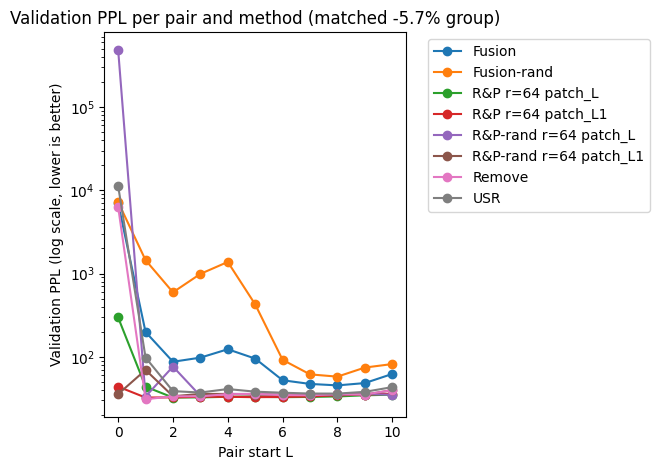

In [27]:
import matplotlib.pyplot as plt
piv = df.pivot_table(index="L", columns="Method", values="PPL", aggfunc="mean")
display(piv)
for c in piv.columns:
    plt.plot(piv.index, piv[c], marker="o", label=c)
plt.yscale("log")
plt.xlabel("Pair start L"); plt.ylabel("Validation PPL (log scale, lower is better)")
plt.title("Validation PPL per pair and method (matched -5.7% group)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left"); plt.tight_layout(); plt.show()

In [28]:
# Mean/min summary across pairs - backs the one-paragraph pattern write-up.
summary = df.groupby("Method")["PPL"].agg(["mean", "min", "std"])
display(summary.sort_values("mean"))
best_per_pair = df.sort_values("PPL").groupby("L").first()[["Pair", "Method", "PPL"]]
display(best_per_pair)

,mean,min,std
Method,,,
R&P r=64 patch_L1,34.553061,32.438128,3.291126
R&P-rand r=64 patch_L1,38.795002,33.634621,10.309804
R&P r=64 patch_L,58.242280,32.438128,79.155333
Remove,607.105033,30.945605,1897.575750
Fusion,711.210052,45.408029,2074.722095
USR,1064.295796,36.177915,3382.685265
Fusion-rand,1129.831619,57.834721,2088.908313
R&P-rand r=64 patch_L,44254.870546,33.332564,146646.963975


,Pair,Method,PPL
L,,,
0,0-1,R&P-rand r=64 patch_L1,35.670356
1,1-2,Remove,30.945605
2,2-3,R&P r=64 patch_L,32.438128
3,3-4,R&P r=64 patch_L,32.577744
4,4-5,R&P r=64 patch_L,33.125244
5,5-6,R&P r=64 patch_L1,32.760023
6,6-7,R&P r=64 patch_L,32.760023
7,7-8,R&P r=64 patch_L,32.999259
8,8-9,R&P r=64 patch_L,33.438760


Method,Fusion,Fusion-rand,R&P r=64 patch_L,R&P r=64 patch_L1,R&P-rand r=64 patch_L,R&P-rand r=64 patch_L1,Remove,USR
L,,,,,,,,
0,1.3370,1.6458,0.1055,0.0214,0.6130,0.2351,1.5353,1.7881
1,0.2219,0.2044,0.0044,0.0053,0.0225,0.6594,0.0114,0.1016
2,0.4544,0.5416,0.0059,0.0059,0.1243,0.0115,0.0128,1.3055
3,0.0593,0.1796,0.0061,0.0057,0.0126,0.0093,0.0135,0.0117
4,0.0488,0.1395,0.0070,0.0071,0.0124,0.0098,0.0124,0.0136
5,0.0409,0.1218,0.0076,0.0085,0.0116,0.0111,0.0124,0.0140
6,0.0479,0.1214,0.0098,0.0112,0.0148,0.0148,0.0164,0.0173
7,0.0555,0.0867,0.0128,0.0144,0.0191,0.0203,0.0208,0.0216
8,0.0482,0.0855,0.0161,0.0188,0.0255,0.0283,0.0263,0.0247


Spearman(nMSE, PPL) = 0.814 (p=5.6e-22) over 88 configs


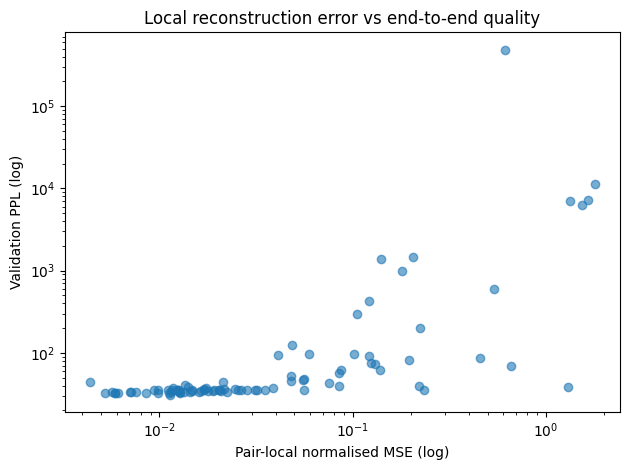

In [29]:
# Local error vs end-to-end quality (brief P6/Q5 spirit): does pair-local nMSE predict PPL damage?
nmse_piv = df.pivot_table(index="L", columns="Method", values="nMSE", aggfunc="mean")
display(nmse_piv.round(4))
from scipy.stats import spearmanr
sub = df[np.isfinite(df["PPL"].astype(float)) & np.isfinite(df["nMSE"].astype(float))]
rho, pval = spearmanr(sub["nMSE"], sub["PPL"])
print(f"Spearman(nMSE, PPL) = {rho:.3f} (p={pval:.2g}) over {len(sub)} configs")
plt.figure()
plt.scatter(sub["nMSE"], sub["PPL"], alpha=0.6)
plt.xscale("log"); plt.yscale("log")
plt.xlabel("Pair-local normalised MSE (log)"); plt.ylabel("Validation PPL (log)")
plt.title("Local reconstruction error vs end-to-end quality")
plt.tight_layout(); plt.show()

## 14. Ablations (I.3 hyperparams)

14a: Q1 rank sweep on the validated best-Remove pair (heatmap + rank curves + delta vs Remove). Expect `r=16 < r=64 ~= r=256` if the lost update is mostly constant + low-rank.

14b: method comparison on the same pair (grouped bars) + USR neuron-mix (stacked bar).

In [30]:
# 14a. Rank x direction on the best-Remove pair (validation).
bestL = int(df[df.Method == "Remove"].sort_values("PPL").iloc[0]["L"])
print("Best Remove pair (validation):", f"{bestL}-{bestL+1}")
Xtr, Y1tr, Y2tr = fit_cache[bestL]
remove_ppl_best = float(df[(df.Method == "Remove") & (df.L == bestL)]["PPL"].iloc[0])
remove_nmse_best = float(df[(df.Method == "Remove") & (df.L == bestL)]["nMSE"].iloc[0])
print(f"Remove baseline on this pair: PPL={remove_ppl_best:.2f} nMSE={remove_nmse_best:.4f}")
abl_rank_rows = []
for r in [16, 64, 256]:
    for d in ["patch_L", "patch_L1"]:
        m, pnm = build_patch_model(bestL, r=r, direction=d, Xtr=Xtr, Y1tr=Y1tr, Y2tr=Y2tr)
        p, n, l = eval_variant(m)
        nm = pair_local_nmse(m, bestL, 2, Xtr, Y2tr)
        abl_rank_rows.append({"rank": r, "direction": d, "PPL": p, "nMSE": nm, "patch_nMSE": pnm, "Params": n, "Lat_ms": l, "dPPL_vs_Remove": p - remove_ppl_best})
        print(f"R&P r={r:3d} {d:8s}: PPL={p:.2f} (d={p - remove_ppl_best:+.2f}) nMSE={nm:.4f} params={n:,}")
        free_model(m)
abl_rank_df = pd.DataFrame(abl_rank_rows)
display(abl_rank_df)

Best Remove pair (validation): 1-2
Remove baseline on this pair: PPL=30.95 nMSE=0.0114


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

R&P r= 16 patch_L : PPL=42.95 (d=+12.00) nMSE=0.0059 params=117,376,512


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

R&P r= 16 patch_L1: PPL=32.68 (d=+1.73) nMSE=0.0064 params=117,376,512


...

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

R&P r=256 patch_L : PPL=43.97 (d=+13.02) nMSE=0.0030 params=117,745,152


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

R&P r=256 patch_L1: PPL=33.06 (d=+2.12) nMSE=0.0040 params=117,745,152


,rank,direction,PPL,nMSE,patch_nMSE,Params,Lat_ms,dPPL_vs_Remove
0,16,patch_L,42.949868,0.005942,0.026873,117376512,20.983325,12.004264
1,16,patch_L1,32.680311,0.006415,0.006415,117376512,20.750064,1.734707
2,64,patch_L,43.836185,0.004369,0.021392,117450240,20.998575,12.890580
3,64,patch_L1,32.438128,0.005256,0.005256,117450240,20.606167,1.492523
4,256,patch_L,43.968510,0.003017,0.015366,117745152,20.987053,13.022906
5,256,patch_L1,33.063243,0.004047,0.004047,117745152,21.068339,2.117639


In [31]:
# 14b. Method comparison on the same pair (Remove / USR / Fusion / Fusion-rand).
m, info = usr_merge(bestL, Xtr); p, n, l = eval_variant(m)
nm = pair_local_nmse(m, bestL, 1, Xtr, Y2tr)
print(f"{'USR':12s}: PPL={p:.2f} nMSE={nm:.4f} kept_L={info['kept_from_L']} kept_L1={info['kept_from_L1']}"); free_model(m)
usr_ppl, usr_n, usr_l, usr_nm, usr_mnm = p, n, l, nm, info["mlp_nmse"]
Xco_best = Xtr[:min(CORR_TOKENS, len(Xtr))]
fusion_rows = []
for tag, rp in [("Fusion", False), ("Fusion-rand", True)]:
    m, finfo = fusion_merge(bestL, Xtr, Xco_best, random_pair=rp, seed=SEED + 1000 * bestL); p, n, l = eval_variant(m)
    nm = pair_local_nmse(m, bestL, 1, Xtr, Y2tr)
    print(f"{tag:12s}: PPL={p:.2f} nMSE={nm:.4f}"); free_model(m)
    fusion_rows.append({"Method": tag, "PPL": p, "nMSE": nm, "mlp_nMSE": finfo["mlp_nmse"], "Params": n, "Lat_ms": l})
rm = df[(df.Method == "Remove") & (df.L == bestL)].iloc[0]
method_cmp_df = pd.DataFrame([{"Method": "Remove", "PPL": remove_ppl_best, "nMSE": remove_nmse_best, "mlp_nMSE": float("nan"), "Params": int(rm["Params"]), "Lat_ms": float(rm["Lat_ms"])}, {"Method": "USR", "PPL": usr_ppl, "nMSE": usr_nm, "mlp_nMSE": usr_mnm, "Params": usr_n, "Lat_ms": usr_l}] + fusion_rows)
method_cmp_df["dPPL_vs_Remove"] = method_cmp_df["PPL"] - remove_ppl_best
display(method_cmp_df)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

USR         : PPL=98.02 nMSE=0.1016 kept_L=1928 kept_L1=1144


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Fusion      : PPL=198.81 nMSE=0.2219


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Fusion-rand : PPL=1449.33 nMSE=0.2044


,Method,PPL,nMSE,mlp_nMSE,Params,Lat_ms,dPPL_vs_Remove
0,Remove,30.945605,0.011391,NaN,117351936,19.993325,0.000000
1,USR,98.020486,0.101603,0.000597,117351936,20.172775,67.074881
2,Fusion,198.805958,0.221927,0.000843,117351936,20.911899,167.860353
3,Fusion-rand,1449.326391,0.204379,0.000840,117351936,20.707567,1418.380786


### 14a visuals - heatmap, rank curves, delta vs Remove

*Read: darker = worse. Flat columns after r=64 mean extra rank buys nothing (low-rank hypothesis holds). A consistent column gap means one direction dominates.*

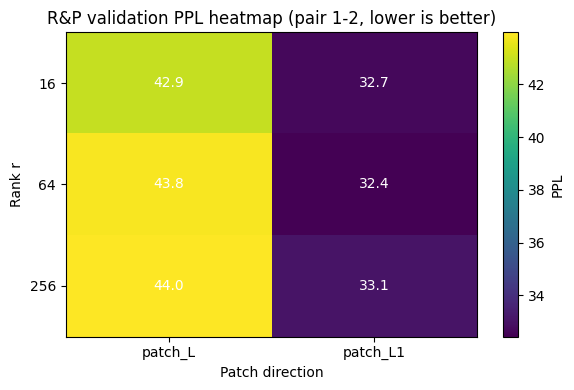

In [32]:
import matplotlib.pyplot as plt
import numpy as np
heat = abl_rank_df.pivot_table(index="rank", columns="direction", values="PPL")
heat = heat.reindex(sorted(heat.index))  # rows come from the table above, never hard-coded
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(heat.values, aspect="auto")
ax.set_xticks(range(len(heat.columns)), list(heat.columns))
ax.set_yticks(range(len(heat.index)), [str(r) for r in heat.index])
ax.set_xlabel("Patch direction"); ax.set_ylabel("Rank r")
ax.set_title(f"R&P validation PPL heatmap (pair {bestL}-{bestL+1}, lower is better)")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.1f}", ha="center", va="center", fontsize=10, color="white")
fig.colorbar(im, ax=ax, label="PPL")
plt.tight_layout(); plt.show()

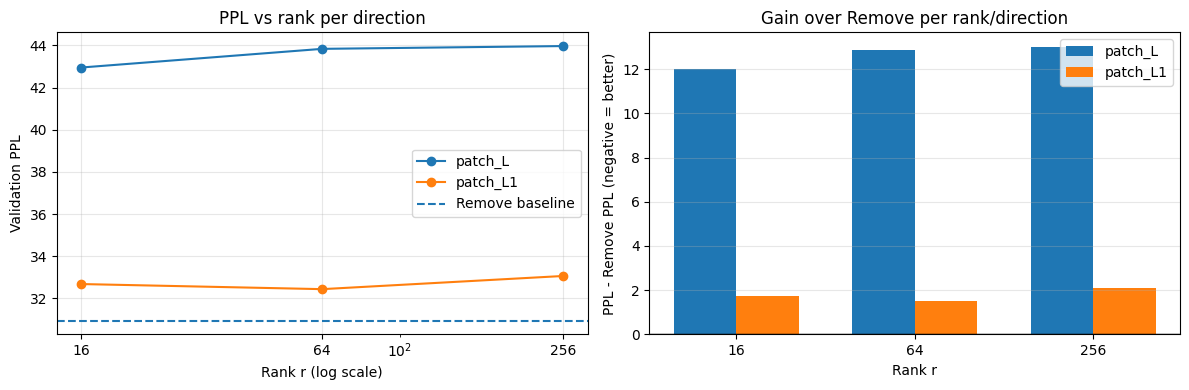

In [33]:
# Rank curves per direction + improvement over Remove.
# Ranks/directions are read from the table above, so a partial/stale 14a run fails loudly instead of here.
ranks = sorted(abl_rank_df["rank"].unique().tolist())
dirs = [d for d in ["patch_L", "patch_L1"] if d in set(abl_rank_df["direction"].tolist())]
assert ranks and dirs, f"abl_rank_df is empty or partial:\n{abl_rank_df}"
vals = {d: [float(abl_rank_df[(abl_rank_df["rank"] == r) & (abl_rank_df["direction"] == d)]["PPL"].iloc[0]) for r in ranks] for d in dirs}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for d in dirs:
    axes[0].plot(ranks, vals[d], marker="o", label=d)
axes[0].axhline(remove_ppl_best, linestyle="--", label="Remove baseline")
axes[0].set_xscale("log", subs=[])
axes[0].set_xticks(ranks, [str(r) for r in ranks])
axes[0].set_xlabel("Rank r (log scale)"); axes[0].set_ylabel("Validation PPL")
axes[0].set_title("PPL vs rank per direction"); axes[0].legend(); axes[0].grid(True, alpha=0.3)
x = np.arange(len(ranks)); w = 0.35
for k, d in enumerate(dirs):
    off = (k - (len(dirs) - 1) / 2) * w
    axes[1].bar(x + off, [v - remove_ppl_best for v in vals[d]], w, label=d)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xticks(x, [str(r) for r in ranks])
axes[1].set_xlabel("Rank r"); axes[1].set_ylabel("PPL - Remove PPL (negative = better)")
axes[1].set_title("Gain over Remove per rank/direction"); axes[1].legend(); axes[1].grid(True, axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

### 14b visuals - method bars and USR neuron mix

*Read: all bars share the same pair, so heights are directly comparable. Negative (hatched) delta = beats Remove. The stacked bar shows where USR's surviving neurons came from.*

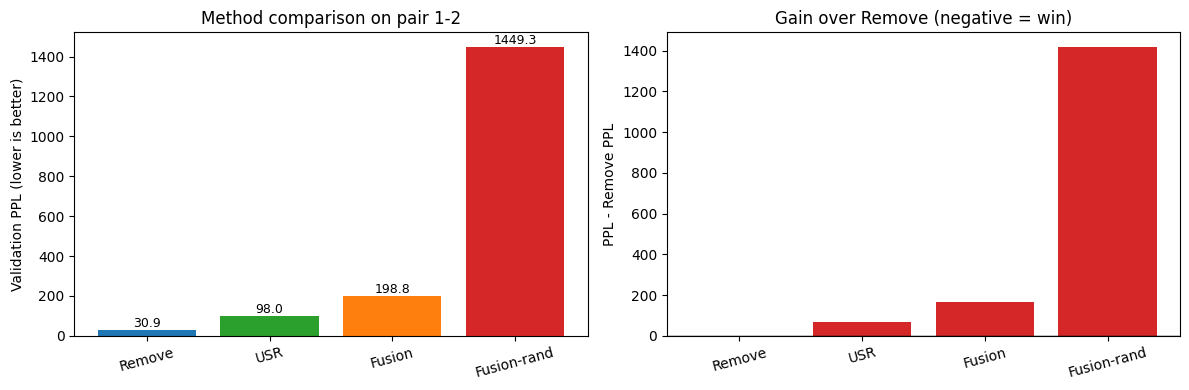

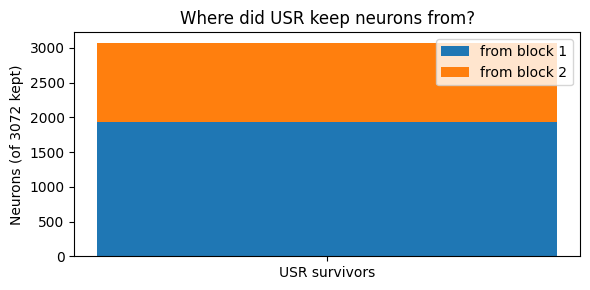

In [34]:
methods = list(method_cmp_df["Method"])
ppls = list(method_cmp_df["PPL"])
colors = ["C0" if m == "Remove" else ("C2" if m == "USR" else ("C1" if m == "Fusion" else "C3")) for m in methods]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(methods, ppls, color=colors)
axes[0].set_ylabel("Validation PPL (lower is better)")
axes[0].set_title(f"Method comparison on pair {bestL}-{bestL+1}")
axes[0].tick_params(axis="x", rotation=15)
for i, v in enumerate(ppls):
    axes[0].text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
deltas = list(method_cmp_df["dPPL_vs_Remove"])
axes[1].bar(methods, deltas, color=["C2" if v < 0 else "C3" for v in deltas])
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_ylabel("PPL - Remove PPL")
axes[1].set_title("Gain over Remove (negative = win)")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["USR survivors"], [info["kept_from_L"]], label=f"from block {bestL}")
ax.bar(["USR survivors"], [info["kept_from_L1"]], bottom=[info["kept_from_L"]], label=f"from block {bestL+1}")
ax.set_ylabel("Neurons (of 3072 kept)")
ax.set_title("Where did USR keep neurons from?")
ax.legend(); plt.tight_layout(); plt.show()

## 15. TEST-once report (no further selection after this)

Best pair per method is frozen from VALIDATION (Section 13); each is scored on TEST exactly once.

In [35]:
best_rows = df.sort_values("PPL").groupby("Method").first().reset_index()
print(best_rows[["Method", "Pair", "Seed", "PPL", "nMSE"]].to_string(index=False))
for _, r in best_rows.iterrows():
    L, mt = int(r["L"]), r["Method"]
    Xtr, Y1tr, Y2tr = fit_cache[L]
    Xco = Xtr[:min(CORR_TOKENS, len(Xtr))]
    if mt == "Remove":
        m = remove_real_block(L)
    elif mt.startswith("R&P"):
        rr = int(re.search(r"r=(\d+)", mt).group(1))
        dd = "patch_L1" if "patch_L1" in mt else "patch_L"
        m, _ = build_patch_model(L, r=rr, direction=dd, Xtr=Xtr, Y1tr=Y1tr, Y2tr=Y2tr, random_subspace=("rand" in mt), seed=(int(r["Seed"]) if not np.isnan(r["Seed"]) else 0))
    elif mt == "USR":
        m, _ = usr_merge(L, Xtr)
    else:
        m, _ = fusion_merge(L, Xtr, Xco, random_pair=("rand" in mt), seed=(int(r["Seed"]) if not np.isnan(r["Seed"]) else SEED + 1000 * L))
    m = m.to(DEVICE)
    pt = calculate_ppl(m, test_text, max_tokens=EVAL_TOKENS)
    print(f"{mt:14s} pair {L}-{L+1} TEST PPL={pt:.2f} (val was {r['PPL']:.2f})")
    free_model(m)
_orig = load_fresh_model().to(DEVICE)
print("Original TEST PPL =", round(calculate_ppl(_orig, test_text, max_tokens=EVAL_TOKENS), 2))
free_model(_orig)

                Method Pair   Seed       PPL     nMSE
                Fusion  8-9    NaN 45.408029 0.048233
           Fusion-rand  8-9 8042.0 57.834721 0.085453
      R&P r=64 patch_L  2-3    NaN 32.438128 0.005922
     R&P r=64 patch_L1  1-2    NaN 32.438128 0.005256
 R&P-rand r=64 patch_L  1-2 1042.0 33.332564 0.022475
R&P-rand r=64 patch_L1  2-3 2042.0 33.634621 0.011516
                Remove  1-2    NaN 30.945605 0.011391
                   USR  8-9    NaN 36.177915 0.024746


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Fusion         pair 8-9 TEST PPL=58.07 (val was 45.41)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Fusion-rand    pair 8-9 TEST PPL=74.96 (val was 57.83)


...

Remove         pair 1-2 TEST PPL=41.26 (val was 30.95)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

USR            pair 8-9 TEST PPL=47.90 (val was 36.18)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Original TEST PPL = 39.58


## 16. Multi-pair merging: 1-5 pairs on 4 datasets (result-format spec)

**Protocol (mirrors the sample format doc):** for steps k=1..5, cumulatively merge k pairs and score WikiText-2 (test), DBpedia (test), AG News (test), IMDb (test).
- **Iterative** (brief P5 style): hidden states are re-collected from the *working* merged model at each step, never chained from stale fits.
- **Order:** per-method greedy plan = best-first non-overlapping pairs from Sec-13 validation PPL; applied in *descending* L so lower pair indices stay valid. Displayed ascending (`4-5; 6-7`).
- **Degradation Doch definition:** `Degradation_% = 100*(PPL_merged - PPL_orig)/PPL_orig` per dataset (sample values like 9.9%/13.2% only make sense as percent increase, not ratio).
- **Columns:** sample's method slots map to ours - `Remove` kept; `LinearMultiply/Average/NonlinearMultiply` slots become `R&P / USR / Fusion` (r=64, validation-winning direction, deterministic). Controls stay in Sec-14 ablations.
- Fitting still uses WikiText-2 TRAIN only; the three new sets are TEST-only eval.

In [36]:
def remove_step(m, L):
    # In-place single-block delete on the working model.
    bs = list(m.transformer.h)
    m.transformer.h = nn.ModuleList(bs[:L] + bs[L+1:])
    m.config.n_layer = len(bs) - 1
    return m

def merge_one_pair(m, L, method, Xtr, Y1tr, Y2tr, Xco):
    # ONE merge applied to working model m. Returns the NEW model (caller frees the old one).
    # Must be applied in descending-L order so lower pair indices stay valid.
    if method == "Remove":
        return remove_step(m, L), {}
    if method == "R&P":
        return build_patch_model(L, r=MP_RP_R, direction=MP_RP_DIR, Xtr=Xtr, Y1tr=Y1tr, Y2tr=Y2tr, src_model=m)
    if method == "USR":
        return usr_merge(L, Xtr, src_model=m)
    if method == "Fusion":
        return fusion_merge(L, Xtr, Xco, src_model=m)
    raise ValueError(method)

def greedy_plan(df, method, k=5):
    # Best-first non-overlapping pair order from Sec-13 validation PPL.
    sub = df[df.Method == method].sort_values("PPL")
    picked, used = [], set()
    for _, r in sub.iterrows():
        L = int(r["L"])
        if {L, L + 1} & used:
            continue
        picked.append(L); used |= {L, L + 1}
        if len(picked) == k:
            break
    return picked

MP_METHODS = ["Remove", "R&P", "USR", "Fusion"]
MP_RP_R = 64
_rp_means = {d: float(df[df.Method == f"R&P r=64 {d}"]["PPL"].mean()) for d in ["patch_L", "patch_L1"]}
MP_RP_DIR = min(_rp_means, key=_rp_means.get)
print("R&P direction for multi-pair (lowest mean val PPL):", MP_RP_DIR,
      {k: round(v, 1) for k, v in _rp_means.items()})
_mp_col = {"R&P": f"R&P r=64 {MP_RP_DIR}"}
plans = {mt: greedy_plan(df, _mp_col.get(mt, mt)) for mt in MP_METHODS}
for mt, pl in plans.items():
    print(f"{mt:8s} merge order: {[f'{l}-{l+1}' for l in sorted(pl)]}")

R&P direction for multi-pair (lowest mean val PPL): patch_L1 {'patch_L': 58.2, 'patch_L1': 34.6}
Remove   merge order: ['1-2', '3-4', '5-6', '7-8', '9-10']
R&P      merge order: ['1-2', '3-4', '5-6', '7-8', '9-10']
USR      merge order: ['1-2', '3-4', '6-7', '8-9', '10-11']
Fusion   merge order: ['2-3', '4-5', '6-7', '8-9', '10-11']


In [37]:
EVAL_SETS = {"WikiText-2": (test_text, EVAL_TOKENS),
             "DBpedia": (dbpedia_text, NEW_EVAL_TOKENS),
             "AG News": (ag_text, NEW_EVAL_TOKENS),
             "IMDb": (imdb_text, NEW_EVAL_TOKENS)}
_tmp = load_fresh_model()
_orig_params = parameter_count(_tmp)
del _tmp; gc.collect()

deg_rows = []
prop_tables = {}
for mt in MP_METHODS:
    plan = plans[mt]
    print(f"\n===== {mt}: plan {[f'{l}-{l+1}' for l in sorted(plan)]} =====")
    m = load_fresh_model().to(DEVICE)
    step_ppl = {0: {name: calculate_ppl(m, txt, max_tokens=cap) for name, (txt, cap) in EVAL_SETS.items()}}
    step_params = {0: parameter_count(m)}
    done = []
    for k, L in enumerate(sorted(plan, reverse=True), start=1):
        Xtr, Y1tr, Y2tr = collect_pair_states(m, train_text, L, total_tokens=FIT_TOKENS)
        Xco = Xtr[:min(CORR_TOKENS, len(Xtr))]
        old = m
        m, _ = merge_one_pair(m, L, mt, Xtr, Y1tr, Y2tr, Xco)
        free_model(old)
        done.append(L)
        step_ppl[k] = {name: calculate_ppl(m, txt, max_tokens=cap) for name, (txt, cap) in EVAL_SETS.items()}
        step_params[k] = parameter_count(m)
        print(f"[{mt}] step {k}: merged {L}-{L+1} " +
              " ".join(f"{name}={step_ppl[k][name]:.1f}" for name in EVAL_SETS))
    free_model(m)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    rows = []
    for k in range(0, len(plan) + 1):
        o = step_ppl[0]
        for name in EVAL_SETS:
            if k == 0:
                continue
            deg_rows.append({"Dataset": name, "Steps": k, "Method": mt,
                             "PPL": round(step_ppl[k][name], 2),
                             "Degradation_%": round(100.0 * (step_ppl[k][name] - o[name]) / o[name], 1)})
        rows.append({"Steps": k,
                     "Merge plan": "(none)" if k == 0 else "; ".join(f"{l}-{l+1}" for l in sorted(done[:k])),
                     "Parameter reduction": f"{100.0 * (1 - step_params[k] / _orig_params):.2f}%",
                     **{f"{name} PPL": round(step_ppl[k][name], 2) for name in EVAL_SETS}})
    prop_tables[mt] = pd.DataFrame(rows)
print("\nmulti-pair loop done")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]


===== Remove: plan ['1-2', '3-4', '5-6', '7-8', '9-10'] =====


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[Remove] step 1: merged 9-10 WikiText-2=47.1 DBpedia=39.8 AG News=52.3 IMDb=43.2
[Remove] step 2: merged 7-8 WikiText-2=59.0 DBpedia=50.1 AG News=64.9 IMDb=52.6
[Remove] step 3: merged 5-6 WikiText-2=82.8 DBpedia=67.5 AG News=90.3 IMDb=65.8
[Remove] step 4: merged 3-4 WikiText-2=122.9 DBpedia=89.1 AG News=134.0 IMDb=88.6
[Remove] step 5: merged 1-2 WikiText-2=145.1 DBpedia=103.7 AG News=150.9 IMDb=101.6

===== R&P: plan ['1-2', '3-4', '5-6', '7-8', '9-10'] =====


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[R&P] step 1: merged 9-10 WikiText-2=45.7 DBpedia=45.3 AG News=56.0 IMDb=45.2
[R&P] step 2: merged 7-8 WikiText-2=56.0 DBpedia=57.1 AG News=74.7 IMDb=58.9
[R&P] step 3: merged 5-6 WikiText-2=71.7 DBpedia=76.6 AG News=114.1 IMDb=77.8
[R&P] step 4: merged 3-4 WikiText-2=91.6 DBpedia=105.2 AG News=168.3 IMDb=101.7
[R&P] step 5: merged 1-2 WikiText-2=137.9 DBpedia=175.0 AG News=309.9 IMDb=163.1

===== USR: plan ['1-2', '3-4', '6-7', '8-9', '10-11'] =====


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[USR] step 1: merged 10-11 WikiText-2=55.7 DBpedia=54.4 AG News=68.1 IMDb=49.9
[USR] step 2: merged 8-9 WikiText-2=73.6 DBpedia=71.6 AG News=100.9 IMDb=65.7
[USR] step 3: merged 6-7 WikiText-2=105.2 DBpedia=102.9 AG News=153.7 IMDb=89.0
[USR] step 4: merged 3-4 WikiText-2=138.6 DBpedia=148.5 AG News=219.8 IMDb=117.3
[USR] step 5: merged 1-2 WikiText-2=421.9 DBpedia=471.0 AG News=751.4 IMDb=334.7

===== Fusion: plan ['2-3', '4-5', '6-7', '8-9', '10-11'] =====


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[Fusion] step 1: merged 10-11 WikiText-2=74.4 DBpedia=82.4 AG News=121.7 IMDb=69.0
[Fusion] step 2: merged 8-9 WikiText-2=116.3 DBpedia=119.2 AG News=176.2 IMDb=102.8
[Fusion] step 3: merged 6-7 WikiText-2=162.5 DBpedia=172.3 AG News=264.2 IMDb=154.3
[Fusion] step 4: merged 4-5 WikiText-2=363.0 DBpedia=359.0 AG News=643.8 IMDb=327.8
[Fusion] step 5: merged 2-3 WikiText-2=844.4 DBpedia=943.9 AG News=1435.3 IMDb=588.4

multi-pair loop done


## 17. Result file: sample-format tables (Table 1 + Table 2)

**Table 1** = PPL degradation % by Dataset x Steps (rows) x Method (columns), exactly the sample's layout (WikiText-2 added as a 4th dataset block). **Table 2** = one proposed-model table per method: steps, cumulative merge plan, exact parameter reduction, absolute PPL per dataset. Both are displayed and saved as CSVs - download them from Colab's Files pane as the neat result file.

In [38]:
deg_df = pd.DataFrame(deg_rows)
t1 = deg_df.pivot_table(index=["Dataset", "Steps"], columns="Method", values="Degradation_%", aggfunc="mean")
t1 = t1.loc[(["WikiText-2", "DBpedia", "AG News", "IMDb"], [1, 2, 3, 4, 5]), MP_METHODS]
print("===== TABLE 1: PPL degradation % vs original (rows: Dataset x merged-pair Steps) =====")
display(t1.round(1))
deg_df.to_csv("table1_degradation_pct.csv", index=False)
for mt in MP_METHODS:
    print(f"\n===== TABLE 2 (proposed model: {mt}) =====")
    display(prop_tables[mt])
    prop_tables[mt].to_csv(f"table2_proposed_{mt}.csv", index=False)
print("\nCSVs written: table1_degradation_pct.csv + table2_proposed_*.csv (Colab Files pane -> download)")

===== TABLE 1: PPL degradation % vs original (rows: Dataset x merged-pair Steps) =====


Method            Remove    R&P     USR  Fusion
Dataset    Steps                               
WikiText-2 1        19.1   15.5    40.7    88.1
           2        49.0   41.5    85.9   193.9
           3       109.1   81.3   165.7   310.5
           4       210.4  131.5   250.3   817.2
           5       266.6  248.5   965.9  2033.4
DBpedia    1         6.7   21.4    45.9   121.0
           2        34.3   53.3    92.0   219.8
           3        81.2  105.4   175.9   362.2
           4       138.9  182.1   298.4   863.0
           5       178.1  369.3  1163.4  2432.0
AG News    1        15.7   23.8    50.8   169.3
           2        43.5   65.4   123.2   290.0
           3        99.9  152.6   240.1   484.7
           4       196.6  272.5   386.4  1324.8
           5       234.0  585.8  1563.0  3076.5
IMDb       1        13.9   19.1    31.7    82.1
           2        38.7   55.4    73.3   171.2
           3        73.6  105.2   134.7   307.0
           4       133.8  168.3   209.4   764.9
           5       167.9  330.2   783.1  1452.2


===== TABLE 2 (proposed model: Remove) =====


,Steps,Merge plan,Parameter reduction,WikiText-2 PPL,DBpedia PPL,AG News PPL,IMDb PPL
0,0,(none),0.00%,39.58,37.28,45.19,37.90
1,1,9-10,5.70%,47.13,39.79,52.27,43.16
2,2,7-8; 9-10,11.39%,58.98,50.05,64.86,52.59
3,3,5-6; 7-8; 9-10,17.09%,82.76,67.53,90.34,65.79
4,4,3-4; 5-6; 7-8; 9-10,22.78%,122.85,89.08,134.04,88.61
5,5,1-2; 3-4; 5-6; 7-8; 9-10,28.48%,145.08,103.66,150.91,101.57



===== TABLE 2 (proposed model: R&P) =====


...


===== TABLE 2 (proposed model: USR) =====


,Steps,Merge plan,Parameter reduction,WikiText-2 PPL,DBpedia PPL,AG News PPL,IMDb PPL
0,0,(none),0.00%,39.58,37.28,45.19,37.90
1,1,10-11,5.70%,55.69,54.37,68.13,49.92
2,2,8-9; 10-11,11.39%,73.59,71.57,100.87,65.68
3,3,6-7; 8-9; 10-11,17.09%,105.15,102.87,153.70,88.97
4,4,3-4; 6-7; 8-9; 10-11,22.78%,138.63,148.50,219.77,117.28
5,5,1-2; 3-4; 6-7; 8-9; 10-11,28.48%,421.88,470.98,751.44,334.74



===== TABLE 2 (proposed model: Fusion) =====


,Steps,Merge plan,Parameter reduction,WikiText-2 PPL,DBpedia PPL,AG News PPL,IMDb PPL
0,0,(none),0.00%,39.58,37.28,45.19,37.90
1,1,10-11,5.70%,74.44,82.39,121.71,69.02
2,2,8-9; 10-11,11.39%,116.34,119.20,176.23,102.80
3,3,6-7; 8-9; 10-11,17.09%,162.48,172.29,264.19,154.28
4,4,4-5; 6-7; 8-9; 10-11,22.78%,363.00,359.01,643.83,327.83
5,5,2-3; 4-5; 6-7; 8-9; 10-11,28.48%,844.38,943.92,1435.35,588.38



CSVs written: table1_degradation_pct.csv + table2_proposed_*.csv (Colab Files pane -> download)


## 18. PDF placeholders (report-only items - delete nothing, fill in LaTeX)

- **I.1 Feedback log:** weekly mentor notes since Presentation 1.
- **I.2 SOTA:** MKA / Chain-of-Merging / ZipIt! / LLM-Streamline - which have code, what you reuse.
- **I.3 System effort/demo:** T4 GPU, RAM, runtime of `full` sweep; viva demo = run Sections 13-15 live.
- **Team contribution:** per-member table at end of report.

**Expected pattern to confirm:** mid-layer pairs merge best; R&P/Fusion/USR beat Remove+Average at matched params; early pair 0-1 collapses for all.